In [ ]:

import pandas as pd

import matplotlib.pyplot as plt
  
import seaborn as sns
data=pd.read_csv('./googleplaystore_cleaned.csv')







On regarde la repartition des applications gratuites vs payantes

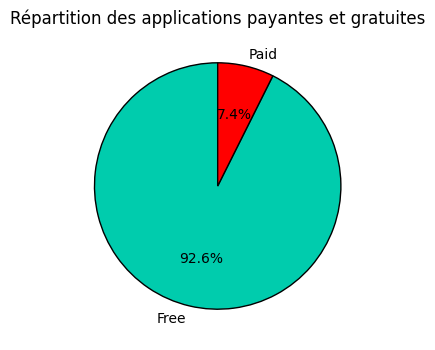

In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(4,4))
data['Type'].value_counts().plot.pie(autopct='%1.1f%%', colors=["#00ccad","#ff0000"], startangle=90, wedgeprops={'edgecolor': 'black'})
plt.title("Répartition des applications payantes et gratuites")
plt.ylabel("")  # Cacher le label de l'axe Y
plt.show()


Ici on regarde les gammes de prix pour chaque catégorie d'application , on remarque que les plus chers sont dans la finance

C:\Users\fatal\AppData\Local\Temp\ipykernel_66464\1987273710.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data[data['Type'] == 'Paid'], x="Category", y="Price", alpha=1, palette=["#00ccad","#ff0000","#ffcb01","#009245"])
C:\Users\fatal\AppData\Local\Temp\ipykernel_66464\1987273710.py:2: UserWarning: 
The palette list has fewer values (4) than needed (30) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=data[data['Type'] == 'Paid'], x="Category", y="Price", alpha=1, palette=["#00ccad","#ff0000","#ffcb01","#009245"])


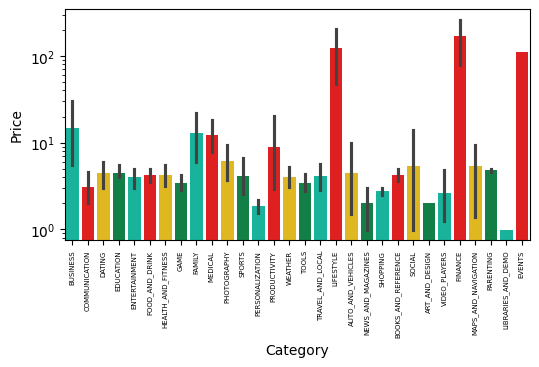

In [37]:
plt.figure(figsize=(6,3))
sns.barplot(data=data[data['Type'] == 'Paid'], x="Category", y="Price", alpha=1, palette=["#00ccad","#ff0000","#ffcb01","#009245"])
plt.xticks(rotation=90,fontsize=5)
plt.yscale('log')  # Mettre l'échelle en logarithmique pour mieux visualiser les prix
plt.show()

Ce graphique représente la corrélation entre le prix et le nombre de téléchargement et notes

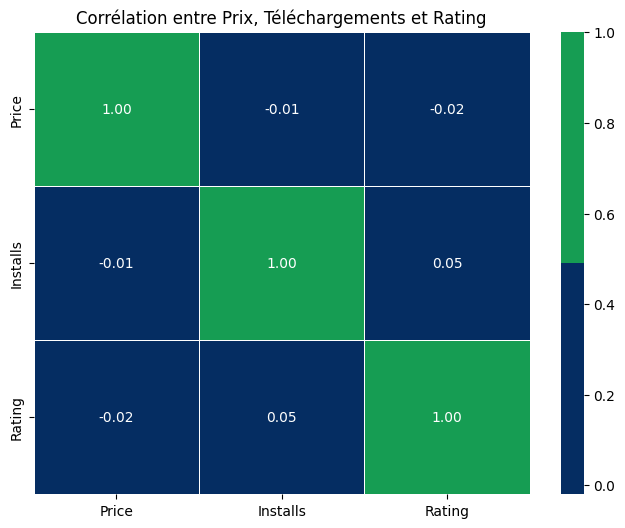

In [ ]:


# Calculer la matrice de corrélation
correlation_matrix = data[['Price', 'Installs', 'Rating']].corr()

# Affichage de la heatmap
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap=["#00ccadc","#ff0000","#ffcb01","#009245"], fmt=".2f", linewidths=0.5)

plt.title("Corrélation entre Prix, Téléchargements et Rating")
plt.show()

Ici c'est pour vérifier si les prix ont un réel impact sur le nombre de téléchargement

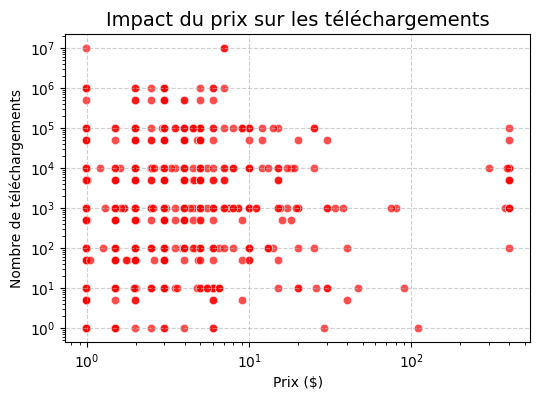

In [38]:


plt.figure(figsize=(6, 4))

# Scatterplot Prix vs Téléchargements
sns.scatterplot(data=data[data['Type'] == 'Paid'], x="Price", y="Installs", alpha=0.7,color="#ff0000")

plt.xlabel("Prix ($)")
plt.ylabel("Nombre de téléchargements")
plt.title("Impact du prix sur les téléchargements", fontsize=14)
#plt.xscale("log")  # Log scale pour mieux voir la répartition des prix
plt.yscale("log")  # Log scale pour voir les grands écarts de téléchargements
plt.xscale("log")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()



On regarde si les notes changent vraiment selon que l'application soit payante ou gratuite

C:\Users\fatal\AppData\Local\Temp\ipykernel_66464\204842499.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x="Type", y="Rating", palette={"Free": "#ffcb01", "Paid":"#009245"})


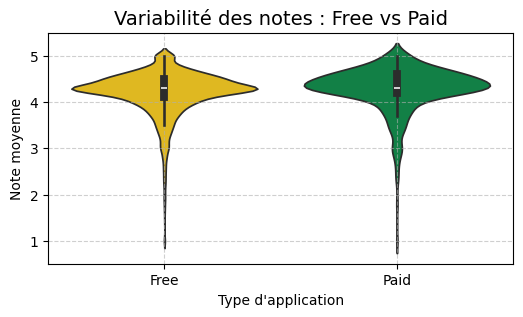

In [29]:
plt.figure(figsize=(6, 3))

# Violin plot avec couleurs Google Play
sns.violinplot(data=data, x="Type", y="Rating", palette={"Free": "#ffcb01", "Paid":"#009245"})

plt.xlabel("Type d'application")
plt.ylabel("Note moyenne")
plt.title("Variabilité des notes : Free vs Paid", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Ici on regarde le nombre d'application payante ou gratuite pour chaque catégorie 

<Figure size 1400x800 with 0 Axes>

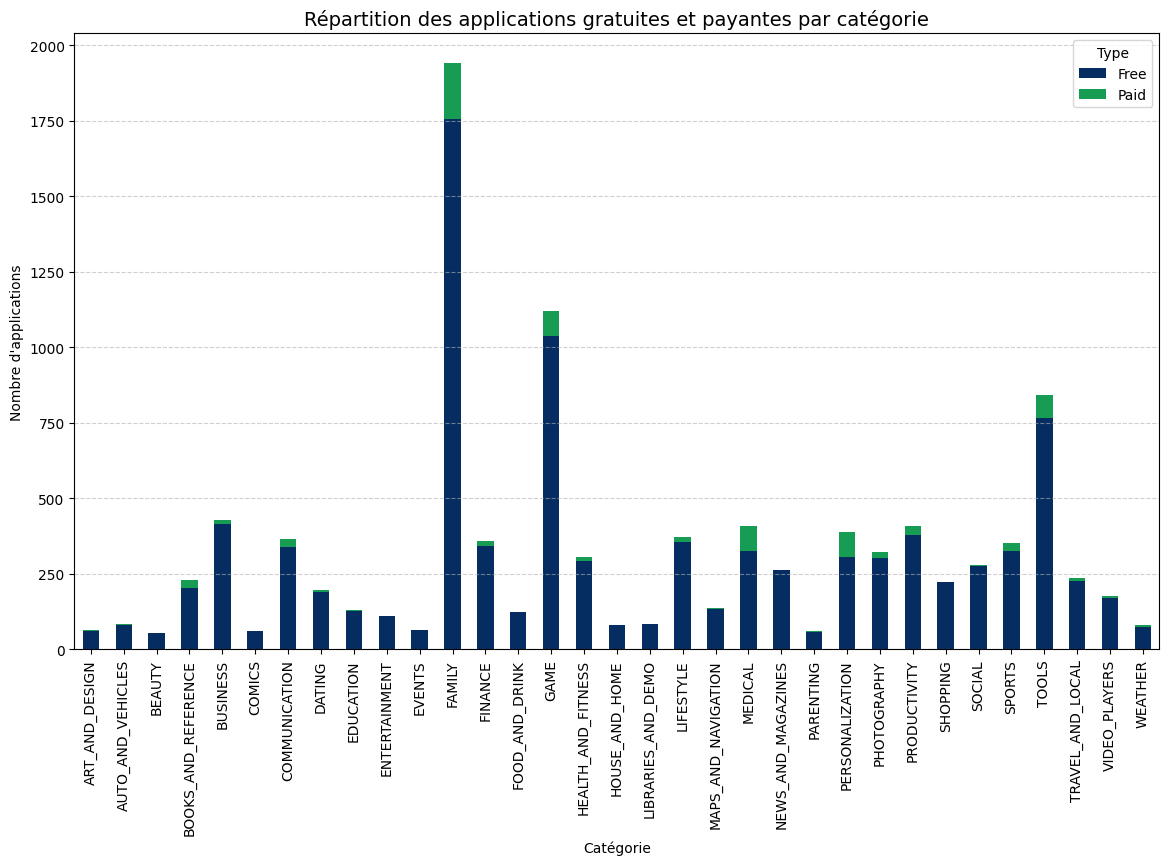

In [8]:
plt.figure(figsize=(14, 8))

# Compter le nombre d'apps Free/Paid par catégorie
category_type_counts = data.groupby(["Category", "Type"]).size().unstack(fill_value=0)

# Stacked barplot avec couleurs Google Play
category_type_counts.plot(kind="bar", stacked=True, figsize=(14, 8), 
                          color={"Free": "#052d62", "Paid": "#169d53"})

plt.xlabel("Catégorie")
plt.ylabel("Nombre d'applications")
plt.title("Répartition des applications gratuites et payantes par catégorie", fontsize=14)
plt.xticks(rotation=90)
plt.legend(title="Type")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()